"ShopSmart E-Commerce — End-to-End Business Intelligence Analysis" 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px


In [3]:
df=pd.read_csv("../../datasets/orders datasets.csv")

PART A: DATA LOADING & EXPLORATION (15 Marks) 

Display the first 10 rows 

In [4]:
df.head(11)

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating
0,1001,05/01/2024,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0
1,1002,07/01/2024,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0
2,1003,07/01/2024,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0
3,1004,10/01/2024,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN
4,1005,12/01/2024,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0
5,1006,15/01/2024,Ayesha Bibi,Female,31,Peshawar,Desk Lamp,Home & Kitchen,1,2200,0,Debit Card,Delivered,3.0
6,1007,18/01/2024,Bilal Shah,Male,27,Quetta,Wireless Mouse,Electronics,3,1500,10,Credit Card,Returned,2.0
7,1008,20/01/2024,Hina Tariq,Female,38,Karachi,Cooking Pan Set,Home & Kitchen,1,5500,25,Cash on Delivery,Delivered,4.0
8,1009,22/01/2024,Zain Malik,Male,24,Islamabad,Data Science Book,Books,2,2200,10,Debit Card,Delivered,5.0
9,1010,25/01/2024,Mehreen Aslam,Female,42,Lahore,Resistance Bands,Sports,4,800,0,Credit Card,Delivered,4.0


 last 5 rows of the dataset 

In [5]:
df.tail(5)

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating
145,1146,30/08/2024,Adnan Siddiqui,Male,34,Rawalpindi,SQL Handbook,Books,1,1600,5,Debit Card,Delivered,4.0
146,1147,30/09/2024,Saima Noor,Female,40,Sukkur,Blender,Home & Kitchen,1,6800,10,Credit Card,Returned,2.0
147,1148,30/10/2024,Yasir Hussain,Male,26,Multan,Sneakers,Fashion,1,9500,20,Cash on Delivery,Delivered,5.0
148,1149,28/11/2024,Iqra Kanwal,Female,24,Faisalabad,Webcam,Electronics,1,5200,10,Debit Card,Delivered,4.0
149,1150,28/12/2024,Arslan Butt,Male,38,Hyderabad,Cricket Bat,Sports,1,8500,5,Credit Card,Delivered,5.0


shape of the dataset 


In [6]:
df.shape

(150, 14)

How many columns and rows exist in the dataset 

In [7]:
df.shape[0]

150

the dataset has 150 rows

In [8]:
df.shape[1]

14

and 14 columns

Print all column names and data types of each column 

In [9]:
df.dtypes

order_id              int64
order_date              str
customer_name           str
customer_gender         str
customer_age          int64
customer_city           str
product_name            str
category                str
quantity              int64
unit_price            int64
discount_percent      int64
payment_method          str
order_status            str
rating              float64
dtype: object

Use .info() to display the concise summary of the DataFrame

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          150 non-null    int64  
 1   order_date        150 non-null    str    
 2   customer_name     150 non-null    str    
 3   customer_gender   150 non-null    str    
 4   customer_age      150 non-null    int64  
 5   customer_city     150 non-null    str    
 6   product_name      150 non-null    str    
 7   category          150 non-null    str    
 8   quantity          150 non-null    int64  
 9   unit_price        150 non-null    int64  
 10  discount_percent  150 non-null    int64  
 11  payment_method    150 non-null    str    
 12  order_status      150 non-null    str    
 13  rating            142 non-null    float64
dtypes: float64(1), int64(5), str(8)
memory usage: 16.5 KB


Check for null/missing values in every column and display the count. Which column(s) have missing data? 

In [11]:
df.isnull().sum()


order_id            0
order_date          0
customer_name       0
customer_gender     0
customer_age        0
customer_city       0
product_name        0
category            0
quantity            0
unit_price          0
discount_percent    0
payment_method      0
order_status        0
rating              8
dtype: int64

there are only 8 missing values

Checking for duplicate rows based on order_id.


In [12]:
df = df.drop_duplicates(subset=["order_id"])
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating
0,1001,05/01/2024,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0
1,1002,07/01/2024,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0
2,1003,07/01/2024,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0
3,1004,10/01/2024,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN
4,1005,12/01/2024,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0


Convert the order_date column from object/string to proper datetime format using pd.to_datetime() 


In [13]:
df["order_date"] = pd.to_datetime(df["order_date"], dayfirst=True)
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0


Create a new column total_price = quantity × unit_price 

In [14]:
df["total_price"] = df["quantity"] * df["unit_price"]
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN,4500
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000


 Create a new column discount_amount = total_price × (discount_percent / 100) 

In [15]:
df["discount_amount"]=df["total_price"] * (df["discount_percent"] / 100)
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN,4500,900.0
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0


Create a new column final_amount = total_price − discount_amount

In [16]:
df["Final_amount"]=df["total_price"] - df["discount_amount"]
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN,4500,900.0,3600.0
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0


Create a new column order_month_name extracting the month name (January, February, etc.) from order_date 

In [17]:
df['order_month_name'] = df['order_date'].dt.month_name()
df.tail(5)

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name
145,1146,2024-08-30,Adnan Siddiqui,Male,34,Rawalpindi,SQL Handbook,Books,1,1600,5,Debit Card,Delivered,4.0,1600,80.0,1520.0,August
146,1147,2024-09-30,Saima Noor,Female,40,Sukkur,Blender,Home & Kitchen,1,6800,10,Credit Card,Returned,2.0,6800,680.0,6120.0,September
147,1148,2024-10-30,Yasir Hussain,Male,26,Multan,Sneakers,Fashion,1,9500,20,Cash on Delivery,Delivered,5.0,9500,1900.0,7600.0,October
148,1149,2024-11-28,Iqra Kanwal,Female,24,Faisalabad,Webcam,Electronics,1,5200,10,Debit Card,Delivered,4.0,5200,520.0,4680.0,November
149,1150,2024-12-28,Arslan Butt,Male,38,Hyderabad,Cricket Bat,Sports,1,8500,5,Credit Card,Delivered,5.0,8500,425.0,8075.0,December


 Create a new column order_quarter extracting the quarter (Q1, Q2, Q3, Q4) from order_date 
 

In [18]:
df['order_quarter'] = 'Q' + df['order_date'].dt.quarter.astype(str)
df

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN,4500,900.0,3600.0,January,Q1
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,1146,2024-08-30,Adnan Siddiqui,Male,34,Rawalpindi,SQL Handbook,Books,1,1600,5,Debit Card,Delivered,4.0,1600,80.0,1520.0,August,Q3
146,1147,2024-09-30,Saima Noor,Female,40,Sukkur,Blender,Home & Kitchen,1,6800,10,Credit Card,Returned,2.0,6800,680.0,6120.0,September,Q3
147,1148,2024-10-30,Yasir Hussain,Male,26,Multan,Sneakers,Fashion,1,9500,20,Cash on Delivery,Delivered,5.0,9500,1900.0,7600.0,October,Q4
148,1149,2024-11-28,Iqra Kanwal,Female,24,Faisalabad,Webcam,Electronics,1,5200,10,Debit Card,Delivered,4.0,5200,520.0,4680.0,November,Q4


Create a new column age_group based on customer_age: • 18–25 → "Young Adult" • 26–35 → "Adult" • 36–45 → "Middle Aged" • 46–60 → "Senior" 

In [19]:
df['age_group'] = pd.cut(
    df['customer_age'],
    bins=[17, 25, 35, 45, 60],
    labels=['Young Adult', 'Adult', 'Middle Aged', 'Senior']
)
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1,Adult
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,NaN,4500,900.0,3600.0,January,Q1,Adult
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged


fill the missing values in the rating column with the median rating value 


In [20]:
df['rating'].median()

np.float64(4.0)

In [21]:
df['rating'] = df['rating'].fillna(df['rating'].median())
df.head()

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1,Adult
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,4.0,4500,900.0,3600.0,January,Q1,Adult
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged


*the median of the rating column is 4.0. By using the fillna() function with the median() method, we filled all the missing values in the rating column with the median value.

Display the first 5 rows after all transformations to verify correctness

In [22]:
df.head(5)

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1,Adult
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,4.0,4500,900.0,3600.0,January,Q1,Adult
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged


PART B: DATA ANALYSIS WITH PANDAS (30 Marks)

1. Print the descriptive statistics of all numeric columns using .describe() 

In [23]:
df.describe()

,order_id,order_date,customer_age,quantity,unit_price,discount_percent,rating,total_price,discount_amount,Final_amount
count,150.000000,150,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,1075.500000,2024-07-15 11:12:00,33.080000,1.713333,3975.666667,8.333333,4.133333,5536.000000,519.683333,5016.316667
min,1001.000000,2024-01-05 00:00:00,21.000000,1.000000,650.000000,0.000000,2.000000,1500.000000,0.000000,1350.000000
25%,1038.250000,2024-04-12 18:00:00,27.000000,1.000000,2050.000000,1.250000,4.000000,3500.000000,20.000000,3200.000000
50%,1075.500000,2024-07-20 00:00:00,31.000000,1.000000,3350.000000,10.000000,4.000000,5400.000000,375.000000,4675.000000
75%,1112.750000,2024-10-23 06:00:00,38.000000,2.000000,5500.000000,13.750000,5.000000,7000.000000,821.250000,6400.000000
max,1150.000000,2024-12-31 00:00:00,52.000000,5.000000,9500.000000,25.000000,5.000000,15000.000000,2600.000000,14250.000000
std,43.445368,NaN,7.857387,0.922039,2412.131925,6.596386,0.747853,2701.615972,525.648153,2378.420915


*We used df.describe() to calculate and display the summary statistics of all numeric columns. It provides information about the count, mean, standard deviation, minimum, quartiles, and maximum

2. What is the average order value (mean of final_amount) across all delivered orders? 

In [24]:
df.loc[df["order_status"] == "Delivered", "Final_amount"].mean()

np.float64(5002.555147058823)

*The average order value of all 136 delivered orders is 5,002.56.

3.What is the maximum single order value? Which product and which customer was it? 

In [25]:
df.loc[df["Final_amount"].idxmax()]

order_id                           1005
order_date          2024-01-12 00:00:00
customer_name                 Usman Ali
customer_gender                    Male
customer_age                         45
customer_city                    Lahore
product_name              Running Shoes
category                         Sports
quantity                              2
unit_price                         7500
discount_percent                      5
payment_method         Cash on Delivery
order_status                  Delivered
rating                              5.0
total_price                       15000
discount_amount                   750.0
Final_amount                    14250.0
order_month_name                January
order_quarter                        Q1
age_group                   Middle Aged
Name: 4, dtype: object

The customer name is Usman Ali and the product he bought is running shoes

4.What is the total revenue generated from Delivered orders only?

In [26]:
Total_revenue= df.loc[df["order_status"] == "Delivered", "Final_amount"].sum()
Total_revenue

np.float64(680347.5)

* the total revenue generated from delivered order is 680347.5

5.How many orders were Cancelled? How many were Returned? How many Delivered? 

In [27]:
print(df["order_status"].value_counts())

order_status
Delivered    136
Cancelled      8
Returned       6
Name: count, dtype: int64


* 8 orders were canceled 6 were returned and 136 were delivered succsessfully.

6.What percentage of total orders were successfully Delivered?

In [28]:
(df["order_status"].eq("Delivered").mean()) * 100

np.float64(90.66666666666666)

*90.67% of the total orders were successfully delivered.

7.What is the median customer age? What is the mode of payment method?

In [29]:

df["payment_method"].mode()[0]


'Credit Card'

In [30]:
df["customer_age"].median()

np.float64(31.0)

* The payment method used most frequently is the credit card
* and the median age of all customer is 31

8.Calculate the correlation between customer_age and final_amount. Is there any relationship?

In [31]:
df["customer_age"].corr(df["Final_amount"])

np.float64(0.10278158540292405)

*the correlation between customer age and final amount is 0.102 which is a very weak positive correlation.

Task 4: GroupBy & Aggregation 

1.Find total revenue generated by each city. Sort from highest to lowest. Which city is #1? 

In [32]:
city_revenue = df.groupby("customer_city")["Final_amount"].sum().sort_values(ascending=False)

city_revenue

customer_city
Karachi       160620.0
Lahore        143045.0
Islamabad     121140.0
Peshawar       72195.0
Quetta         65977.5
Rawalpindi     54940.0
Multan         50075.0
Faisalabad     31855.0
Hyderabad      31455.0
Sukkur         21145.0
Name: Final_amount, dtype: float64

In [33]:
city_revenue.head(1)

customer_city
Karachi    160620.0
Name: Final_amount, dtype: float64

 2.Find total revenue generated by each product category. Which category earns the most? 

In [34]:
category_revenue = df.groupby("category")["Final_amount"].sum().sort_values(ascending=False)
category_revenue

category
Electronics       211850.0
Sports            207970.0
Home & Kitchen    142737.5
Fashion           108740.0
Books              81150.0
Name: Final_amount, dtype: float64

In [35]:
category_revenue.index[0]

'Electronics'

*Electronics earns the most, with total revenue of 211,850.

3.Find the average order value grouped by payment method 


In [36]:
df.groupby("payment_method")["Final_amount"].mean()

payment_method
Cash on Delivery    5103.826531
Credit Card         4894.903846
Debit Card          5057.653061
Name: Final_amount, dtype: float64

*Cash on Delivery has the highest average order value at 5,103.83

4.Count how many orders each customer has placed. Who are the top 5 repeat customers? 

In [37]:
customer_orders = df["customer_name"].value_counts()
customer_orders

customer_name
Ali Khan          7
Sara Ahmed        6
Fatima Noor       6
Usman Ali         6
Hina Tariq        6
Zain Malik        6
Ayesha Bibi       5
Bilal Shah        5
Mehreen Aslam     5
Kamran Javed      5
Nadia Hussain     5
Farhan Saeed      5
Sana Mir          5
Rabia Anwar       5
Hamza Sheikh      5
Imran Qureshi     5
Ahmed Raza        4
Tariq Mehmood     4
Maham Fatima      4
Asad Iqbal        4
Sumbal Riaz       4
Waqar Ahmed       4
Nimra Shahzad     4
Shahid Afridi     4
Kiran Malik       4
Junaid Khan       4
Amina Gul         4
Rashid Khan       1
Sadia Perveen     1
Anwar Hussain     1
Naila Akram       1
Faisal Nawaz      1
Uzma Batool       1
Kashif Raza       1
Tahira Naz        1
Shoaib Akhtar     1
Mehwish Hayat     1
Danish Ali        1
Amna Sheikh       1
Rizwan Malik      1
Huma Javed        1
Adnan Siddiqui    1
Saima Noor        1
Yasir Hussain     1
Iqra Kanwal       1
Arslan Butt       1
Name: count, dtype: int64

In [38]:
customer_orders.head(5)

customer_name
Ali Khan       7
Sara Ahmed     6
Fatima Noor    6
Usman Ali      6
Hina Tariq     6
Name: count, dtype: int64

*Ali Khan,Sara Ahmed,Fatima Noor,Usman Ali,Hina Tariq they are the the repeated customers          


5. Find total quantity sold per product. Which product is the bestseller by units sold? 

In [39]:
product_quantity = df.groupby("product_name")["quantity"].sum().sort_values(ascending=False)
product_quantity

product_name
Resistance Bands         27
Cotton T-Shirt           17
Python Book              15
Desk Lamp                14
Yoga Mat                 13
Water Bottle             12
Data Science Book        12
Wireless Mouse           11
Running Shoes            11
Cooking Pan Set          11
Earbuds                  11
Bluetooth Speaker        10
Keyboard Mechanical      10
Power Bank                9
SQL Handbook              8
Webcam                    7
USB Hub                   6
Bed Sheet Set             5
Blender                   5
Machine Learning Book     5
Football                  5
Sunglasses                5
Leather Wallet            5
Cricket Bat               4
Dumbbells Set             4
Watch                     4
Sneakers                  4
Web Development Book      4
Iron                      3
Name: quantity, dtype: int64

In [40]:
product_quantity.index[0]

'Resistance Bands'

Resistance Bands is the bestseller by units sold.

6.Find the average discount percentage given per category 

In [41]:
df.groupby("category")["discount_percent"].mean()

category
Books              7.291667
Electronics       10.121951
Fashion            9.736842
Home & Kitchen    10.161290
Sports             4.571429
Name: discount_percent, dtype: float64

*Home and Kitchen had the highest average discount (10.16%), while Sports had the lowest (4.57%)

7.Find total revenue by month. Which month had the highest revenue? Which had the lowest? 

In [42]:
monthly_revenue = df.groupby("order_month_name")["Final_amount"].sum().sort_values(ascending=False)
monthly_revenue

order_month_name
November     106825.0
December      87025.0
September     63277.5
August        63170.0
June          60430.0
October       58525.0
May           55560.0
April         54660.0
January       52625.0
February      51735.0
July          50310.0
March         48305.0
Name: Final_amount, dtype: float64

In [43]:
print("Highest:", monthly_revenue.index[0])
print("Lowest:", monthly_revenue.index[-1])

Highest: November
Lowest: March


*Novermber had the highest revenue while March had the lowest

8.Find total revenue by quarter (Q1 vs Q2 vs Q3 vs Q4). Which quarter performed best? 


In [44]:
Quarter_revenue=df.groupby("order_quarter")["Final_amount"].sum()
Quarter_revenue

order_quarter
Q1    152665.0
Q2    170650.0
Q3    176757.5
Q4    252375.0
Name: Final_amount, dtype: float64

Q1,Q2,Q3, and Q4 show quaterly revenue. the quarer with the highest revenue performed best

9.Find the average customer rating per product category

In [45]:
df.groupby ("category")["rating"].mean()

category
Books             4.625000
Electronics       4.097561
Fashion           4.157895
Home & Kitchen    3.774194
Sports            4.142857
Name: rating, dtype: float64

books has the highest average rating

10.Find total revenue by gender. Who spends more — Male or Female customers?

In [46]:
df.groupby("customer_gender")["Final_amount"].sum()

customer_gender
Female    338357.5
Male      414090.0
Name: Final_amount, dtype: float64

* Male customers are alot than females

 11.Find the number of orders by age group. Which age group orders the most? 

In [47]:
df["age_group"].value_counts()

age_group
Adult          77
Middle Aged    37
Young Adult    24
Senior         12
Name: count, dtype: int64

* the number of Adult customers are alot

12.Find revenue by city AND category (multi-level groupby). Which city-category combination is the most profitable? 

In [48]:
df.groupby(["customer_city","category"])["Final_amount"] .sum()

customer_city  category      
Faisalabad     Books              3600.0
               Electronics       10205.0
               Fashion           11250.0
               Home & Kitchen     4400.0
               Sports             2400.0
Hyderabad      Books              3960.0
               Electronics        3210.0
               Fashion            7200.0
               Home & Kitchen     9010.0
               Sports             8075.0
Islamabad      Books             28850.0
               Electronics       27495.0
               Fashion           23200.0
               Home & Kitchen    18390.0
               Sports            23205.0
Karachi        Books             16990.0
               Electronics       44175.0
               Fashion           22450.0
               Home & Kitchen    25985.0
               Sports            51020.0
Lahore         Books             11250.0
               Electronics       59310.0
               Fashion            4000.0
               Home & Kitch

Task 5: Filtering & Conditional Queries [10 Marks]

1.Show all orders where final_amount is greater than PKR 15,000 

In [49]:
df[df["Final_amount"]>1500]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1,Adult
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,4.0,4500,900.0,3600.0,January,Q1,Adult
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,1146,2024-08-30,Adnan Siddiqui,Male,34,Rawalpindi,SQL Handbook,Books,1,1600,5,Debit Card,Delivered,4.0,1600,80.0,1520.0,August,Q3,Adult
146,1147,2024-09-30,Saima Noor,Female,40,Sukkur,Blender,Home & Kitchen,1,6800,10,Credit Card,Returned,2.0,6800,680.0,6120.0,September,Q3,Middle Aged
147,1148,2024-10-30,Yasir Hussain,Male,26,Multan,Sneakers,Fashion,1,9500,20,Cash on Delivery,Delivered,5.0,9500,1900.0,7600.0,October,Q4,Adult
148,1149,2024-11-28,Iqra Kanwal,Female,24,Faisalabad,Webcam,Electronics,1,5200,10,Debit Card,Delivered,4.0,5200,520.0,4680.0,November,Q4,Young Adult


2.Show all Cancelled orders. Which city has the most cancellations? 

In [50]:
df[df["order_status"]=="Cancelled"] ["customer_city"].value_counts()


customer_city
Lahore     3
Quetta     3
Karachi    1
Sukkur     1
Name: count, dtype: int64

*Lahore and quetta has the most cencellation compared to the other cities

3. Show all orders from Karachi customers who paid via Credit Card 

In [51]:
df[(df["customer_city"]=="Karachi")&(df["payment_method"]=="Credit Card")]


,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,4.0,4500,900.0,3600.0,January,Q1,Adult
10,1011,2024-02-01,Ali Khan,Male,28,Karachi,Keyboard Mechanical,Electronics,1,6500,15,Credit Card,Delivered,5.0,6500,975.0,5525.0,February,Q1,Adult
13,1014,2024-02-08,Nadia Hussain,Female,26,Karachi,Python Book,Books,1,1800,10,Credit Card,Delivered,4.0,1800,180.0,1620.0,February,Q1,Adult
19,1020,2024-02-22,Fatima Noor,Female,29,Karachi,Resistance Bands,Sports,2,800,0,Credit Card,Delivered,4.0,1600,0.0,1600.0,February,Q1,Adult
28,1029,2024-03-20,Ali Khan,Male,28,Karachi,Resistance Bands,Sports,5,800,0,Credit Card,Delivered,4.0,4000,0.0,4000.0,March,Q1,Adult
46,1047,2024-05-18,Ali Khan,Male,28,Karachi,Desk Lamp,Home & Kitchen,2,2200,10,Credit Card,Delivered,4.0,4400,440.0,3960.0,May,Q2,Adult


* here are the list of orders from Karachi who paid via Credit Card

4. Show all Electronic orders that were successfully Delivered

In [52]:
df[(df["category"]=="Electronics") & (df["order_status"]=="Delivered")]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
0,1001,2024-01-05,Ali Khan,Male,28,Karachi,Wireless Mouse,Electronics,2,1500,10,Credit Card,Delivered,4.0,3000,300.0,2700.0,January,Q1,Adult
10,1011,2024-02-01,Ali Khan,Male,28,Karachi,Keyboard Mechanical,Electronics,1,6500,15,Credit Card,Delivered,5.0,6500,975.0,5525.0,February,Q1,Adult
17,1018,2024-02-18,Rabia Anwar,Female,29,Karachi,Wireless Mouse,Electronics,2,1500,5,Cash on Delivery,Delivered,3.0,3000,150.0,2850.0,February,Q1,Adult
20,1021,2024-03-01,Imran Qureshi,Male,50,Lahore,Keyboard Mechanical,Electronics,1,6500,10,Cash on Delivery,Delivered,4.0,6500,650.0,5850.0,March,Q1,Senior
24,1025,2024-03-10,Zain Malik,Male,24,Islamabad,Bluetooth Speaker,Electronics,1,4500,15,Debit Card,Delivered,4.0,4500,675.0,3825.0,March,Q1,Young Adult
29,1030,2024-03-22,Sana Mir,Female,33,Quetta,Wireless Mouse,Electronics,1,1500,10,Cash on Delivery,Delivered,3.0,1500,150.0,1350.0,March,Q1,Adult
30,1031,2024-04-02,Farhan Saeed,Male,30,Peshawar,Keyboard Mechanical,Electronics,2,6500,20,Debit Card,Delivered,5.0,13000,2600.0,10400.0,April,Q2,Adult
39,1040,2024-04-25,Hina Tariq,Female,38,Karachi,Wireless Mouse,Electronics,2,1500,5,Debit Card,Delivered,4.0,3000,150.0,2850.0,April,Q2,Middle Aged
41,1042,2024-05-04,Mehreen Aslam,Female,42,Lahore,Keyboard Mechanical,Electronics,1,6500,0,Cash on Delivery,Delivered,5.0,6500,0.0,6500.0,May,Q2,Middle Aged
50,1051,2024-06-01,Tariq Mehmood,Male,39,Rawalpindi,Earbuds,Electronics,2,3500,10,Credit Card,Delivered,4.0,7000,700.0,6300.0,June,Q2,Middle Aged


* Above are the lsit of electronics which were successfull delivered

5. find all customers aged below 25 who ordered books

In [53]:
df[(df["customer_age"]<25) & (df["category"]=="Books")]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
8,1009,2024-01-22,Zain Malik,Male,24,Islamabad,Data Science Book,Books,2,2200,10,Debit Card,Delivered,5.0,4400,440.0,3960.0,January,Q1,Young Adult
18,1019,2024-02-20,Hamza Sheikh,Male,21,Islamabad,Data Science Book,Books,3,2200,15,Debit Card,Delivered,5.0,6600,990.0,5610.0,February,Q1,Young Adult
47,1048,2024-05-20,Hamza Sheikh,Male,21,Islamabad,Data Science Book,Books,1,2200,0,Cash on Delivery,Delivered,5.0,2200,0.0,2200.0,May,Q2,Young Adult
55,1056,2024-06-12,Nimra Shahzad,Female,23,Lahore,Web Development Book,Books,2,2000,10,Debit Card,Delivered,5.0,4000,400.0,3600.0,June,Q2,Young Adult
62,1063,2024-07-06,Ahmed Raza,Male,22,Islamabad,Machine Learning Book,Books,1,2800,5,Credit Card,Delivered,5.0,2800,140.0,2660.0,July,Q3,Young Adult
76,1077,2024-08-18,Zain Malik,Male,24,Islamabad,Machine Learning Book,Books,2,2800,5,Debit Card,Delivered,5.0,5600,280.0,5320.0,August,Q3,Young Adult


* list of all the customers below 25 who bought books

6.show all orders palced in Q4 (October,November,December)

In [54]:
df[df["order_quarter"]== "Q4"]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
90,1091,2024-10-01,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,2,4500,15,Cash on Delivery,Delivered,4.0,9000,1350.0,7650.0,October,Q4,Adult
91,1092,2024-10-04,Usman Ali,Male,45,Lahore,Machine Learning Book,Books,1,2800,10,Debit Card,Delivered,5.0,2800,280.0,2520.0,October,Q4,Middle Aged
92,1093,2024-10-06,Tariq Mehmood,Male,39,Rawalpindi,Yoga Mat,Sports,2,3200,0,Credit Card,Delivered,4.0,6400,0.0,6400.0,October,Q4,Middle Aged
93,1094,2024-10-09,Maham Fatima,Female,25,Faisalabad,Cooking Pan Set,Home & Kitchen,1,5500,20,Cash on Delivery,Delivered,4.0,5500,1100.0,4400.0,October,Q4,Young Adult
94,1095,2024-10-11,Asad Iqbal,Male,32,Multan,Webcam,Electronics,2,5200,10,Debit Card,Delivered,5.0,10400,1040.0,9360.0,October,Q4,Adult
95,1096,2024-10-14,Sumbal Riaz,Female,44,Hyderabad,Cotton T-Shirt,Fashion,4,1200,0,Credit Card,Delivered,3.0,4800,0.0,4800.0,October,Q4,Middle Aged
96,1097,2024-10-16,Waqar Ahmed,Male,27,Karachi,Resistance Bands,Sports,3,800,5,Cash on Delivery,Delivered,4.0,2400,120.0,2280.0,October,Q4,Adult
97,1098,2024-10-19,Nimra Shahzad,Female,23,Lahore,USB Hub,Electronics,2,1800,10,Debit Card,Delivered,5.0,3600,360.0,3240.0,October,Q4,Young Adult
98,1099,2024-10-21,Shahid Afridi,Male,48,Peshawar,Desk Lamp,Home & Kitchen,1,2200,0,Credit Card,Delivered,4.0,2200,0.0,2200.0,October,Q4,Senior
99,1100,2024-10-24,Kiran Malik,Female,36,Quetta,Web Development Book,Books,2,2000,15,Cash on Delivery,Delivered,4.0,4000,600.0,3400.0,October,Q4,Middle Aged


* it displayed all orders which were palced in November,December and October

7. Show all orders where the customer gave a rating of 5

In [55]:
df[df["rating"]== 5]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
1,1002,2024-01-07,Sara Ahmed,Female,34,Lahore,Yoga Mat,Sports,1,3200,0,Cash on Delivery,Delivered,5.0,3200,0.0,3200.0,January,Q1,Adult
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged
8,1009,2024-01-22,Zain Malik,Male,24,Islamabad,Data Science Book,Books,2,2200,10,Debit Card,Delivered,5.0,4400,440.0,3960.0,January,Q1,Young Adult
10,1011,2024-02-01,Ali Khan,Male,28,Karachi,Keyboard Mechanical,Electronics,1,6500,15,Credit Card,Delivered,5.0,6500,975.0,5525.0,February,Q1,Adult
15,1016,2024-02-12,Sana Mir,Female,33,Quetta,Running Shoes,Sports,1,7500,0,Debit Card,Delivered,5.0,7500,0.0,7500.0,February,Q1,Adult
18,1019,2024-02-20,Hamza Sheikh,Male,21,Islamabad,Data Science Book,Books,3,2200,15,Debit Card,Delivered,5.0,6600,990.0,5610.0,February,Q1,Young Adult
23,1024,2024-03-08,Hina Tariq,Female,38,Karachi,Python Book,Books,2,1800,0,Cash on Delivery,Delivered,5.0,3600,0.0,3600.0,March,Q1,Middle Aged
27,1028,2024-03-18,Nadia Hussain,Female,26,Karachi,Data Science Book,Books,1,2200,5,Debit Card,Delivered,5.0,2200,110.0,2090.0,March,Q1,Adult
30,1031,2024-04-02,Farhan Saeed,Male,30,Peshawar,Keyboard Mechanical,Electronics,2,6500,20,Debit Card,Delivered,5.0,13000,2600.0,10400.0,April,Q2,Adult
33,1034,2024-04-10,Rabia Anwar,Female,29,Karachi,Python Book,Books,4,1800,10,Debit Card,Delivered,5.0,7200,720.0,6480.0,April,Q2,Adult


* it dispalyed all orders where customers gave rating of 5

8.Show all orders with discount_percent greater than 15%

In [56]:
df[df["discount_percent"] > 15]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
3,1004,2024-01-10,Fatima Noor,Female,29,Karachi,Bluetooth Speaker,Electronics,1,4500,20,Credit Card,Cancelled,4.0,4500,900.0,3600.0,January,Q1,Adult
7,1008,2024-01-20,Hina Tariq,Female,38,Karachi,Cooking Pan Set,Home & Kitchen,1,5500,25,Cash on Delivery,Delivered,4.0,5500,1375.0,4125.0,January,Q1,Middle Aged
14,1015,2024-02-10,Farhan Saeed,Male,30,Peshawar,Bluetooth Speaker,Electronics,2,4500,20,Cash on Delivery,Returned,2.0,9000,1800.0,7200.0,February,Q1,Adult
22,1023,2024-03-05,Bilal Shah,Male,27,Quetta,Cooking Pan Set,Home & Kitchen,2,5500,20,Credit Card,Cancelled,4.0,11000,2200.0,8800.0,March,Q1,Adult
30,1031,2024-04-02,Farhan Saeed,Male,30,Peshawar,Keyboard Mechanical,Electronics,2,6500,20,Debit Card,Delivered,5.0,13000,2600.0,10400.0,April,Q2,Adult
40,1041,2024-05-01,Zain Malik,Male,24,Islamabad,Cooking Pan Set,Home & Kitchen,1,5500,20,Credit Card,Delivered,4.0,5500,1100.0,4400.0,May,Q2,Young Adult
53,1054,2024-06-08,Sumbal Riaz,Female,44,Hyderabad,Blender,Home & Kitchen,1,6800,20,Credit Card,Delivered,3.0,6800,1360.0,5440.0,June,Q2,Middle Aged
61,1062,2024-07-04,Sara Ahmed,Female,34,Lahore,Sunglasses,Fashion,2,2500,20,Debit Card,Delivered,3.0,5000,1000.0,4000.0,July,Q3,Adult
69,1070,2024-07-24,Waqar Ahmed,Male,27,Karachi,Sneakers,Fashion,1,9500,20,Cash on Delivery,Delivered,4.0,9500,1900.0,7600.0,July,Q3,Adult
77,1078,2024-08-20,Mehreen Aslam,Female,42,Lahore,Webcam,Electronics,1,5200,20,Credit Card,Cancelled,4.0,5200,1040.0,4160.0,August,Q3,Middle Aged


9. find the top 10 highest value orders sorted by Final_amount in descending order

In [57]:
df.sort_values("Final_amount",ascending=False).head(10)

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
4,1005,2024-01-12,Usman Ali,Male,45,Lahore,Running Shoes,Sports,2,7500,5,Cash on Delivery,Delivered,5.0,15000,750.0,14250.0,January,Q1,Middle Aged
42,1043,2024-05-07,Nadia Hussain,Female,26,Karachi,Running Shoes,Sports,2,7500,10,Debit Card,Delivered,4.0,15000,1500.0,13500.0,May,Q2,Adult
100,1101,2024-11-01,Junaid Khan,Male,30,Islamabad,Keyboard Mechanical,Electronics,2,6500,10,Debit Card,Delivered,5.0,13000,1300.0,11700.0,November,Q4,Adult
30,1031,2024-04-02,Farhan Saeed,Male,30,Peshawar,Keyboard Mechanical,Electronics,2,6500,20,Debit Card,Delivered,5.0,13000,2600.0,10400.0,April,Q2,Adult
49,1050,2024-05-25,Imran Qureshi,Male,50,Lahore,Cooking Pan Set,Home & Kitchen,2,5500,10,Credit Card,Delivered,5.0,11000,1100.0,9900.0,May,Q2,Senior
110,1111,2024-11-21,Farhan Saeed,Male,30,Peshawar,Dumbbells Set,Sports,2,5500,10,Credit Card,Delivered,4.0,11000,1100.0,9900.0,November,Q4,Adult
118,1119,2024-12-07,Usman Ali,Male,45,Lahore,Webcam,Electronics,2,5200,5,Debit Card,Delivered,5.0,10400,520.0,9880.0,December,Q4,Middle Aged
94,1095,2024-10-11,Asad Iqbal,Male,32,Multan,Webcam,Electronics,2,5200,10,Debit Card,Delivered,5.0,10400,1040.0,9360.0,October,Q4,Adult
22,1023,2024-03-05,Bilal Shah,Male,27,Quetta,Cooking Pan Set,Home & Kitchen,2,5500,20,Credit Card,Cancelled,4.0,11000,2200.0,8800.0,March,Q1,Adult
106,1107,2024-11-13,Nadia Hussain,Female,26,Karachi,Sneakers,Fashion,1,9500,10,Debit Card,Delivered,4.0,9500,950.0,8550.0,November,Q4,Adult


10.show all orders from lahore or islamabad where quantity is 3 or more

In [58]:
df[(df["customer_city"].isin(["Lahore","Islamabad"])) & (df["quantity"] >=3)]

,order_id,order_date,customer_name,customer_gender,customer_age,customer_city,product_name,category,quantity,unit_price,discount_percent,payment_method,order_status,rating,total_price,discount_amount,Final_amount,order_month_name,order_quarter,age_group
2,1003,2024-01-07,Ahmed Raza,Male,22,Islamabad,Python Book,Books,3,1800,15,Debit Card,Delivered,4.0,5400,810.0,4590.0,January,Q1,Young Adult
9,1010,2024-01-25,Mehreen Aslam,Female,42,Lahore,Resistance Bands,Sports,4,800,0,Credit Card,Delivered,4.0,3200,0.0,3200.0,January,Q1,Middle Aged
18,1019,2024-02-20,Hamza Sheikh,Male,21,Islamabad,Data Science Book,Books,3,2200,15,Debit Card,Delivered,5.0,6600,990.0,5610.0,February,Q1,Young Adult
26,1027,2024-03-15,Kamran Javed,Male,35,Islamabad,Desk Lamp,Home & Kitchen,3,2200,0,Cash on Delivery,Delivered,4.0,6600,0.0,6600.0,March,Q1,Adult
73,1074,2024-08-10,Junaid Khan,Male,30,Islamabad,Cotton T-Shirt,Fashion,5,1200,0,Debit Card,Delivered,4.0,6000,0.0,6000.0,August,Q3,Adult
80,1081,2024-09-01,Imran Qureshi,Male,50,Lahore,Power Bank,Electronics,3,2800,5,Credit Card,Delivered,5.0,8400,420.0,7980.0,September,Q3,Senior
107,1108,2024-11-15,Imran Qureshi,Male,50,Lahore,Python Book,Books,3,1800,5,Credit Card,Delivered,5.0,5400,270.0,5130.0,November,Q4,Senior
109,1110,2024-11-19,Hamza Sheikh,Male,21,Islamabad,Water Bottle,Home & Kitchen,3,650,0,Debit Card,Delivered,3.0,1950,0.0,1950.0,November,Q4,Young Adult
116,1117,2024-12-03,Ahmed Raza,Male,22,Islamabad,Resistance Bands,Sports,3,800,0,Credit Card,Delivered,4.0,2400,0.0,2400.0,December,Q4,Young Adult


Task 6: Matplotlib_Bar & Line Charts (10 Marks)

1. Vertical bar chart___Total revenue by product category

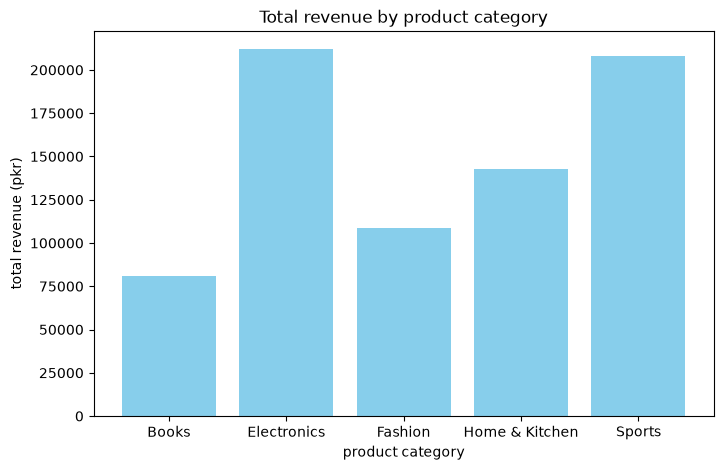

In [59]:
revenue=df.groupby("category")["Final_amount"].sum()
plt.figure(figsize=(8,5))
plt.bar(revenue.index,revenue.values,color="skyblue")
plt.title("Total revenue by product category")
plt.xlabel("product category")
plt.ylabel("total revenue (pkr)")
plt.show()


2.vertical_bar chart ___Number of orders by top 7 cities

<function matplotlib.pyplot.show(close=None, block=None)>

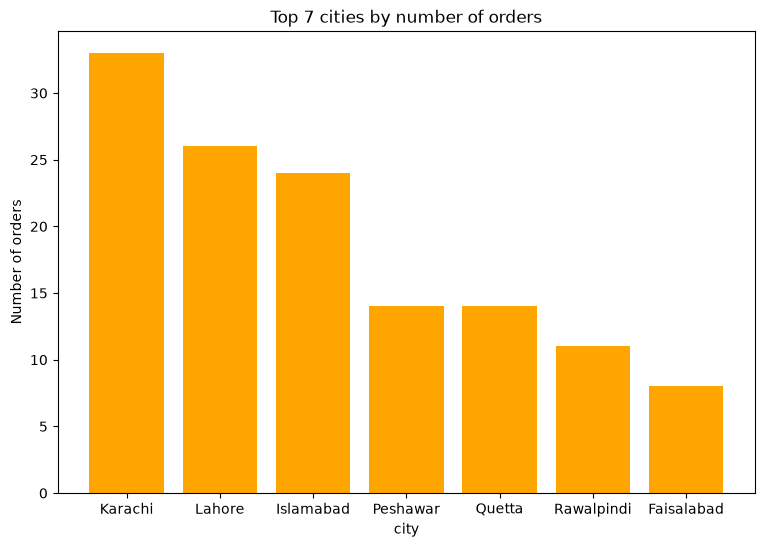

In [60]:
city_orders=df["customer_city"].value_counts().head(7)
plt.figure(figsize=(9,6))
plt.bar(city_orders.index,city_orders.values, color="orange")
plt.title("Top 7 cities by number of orders")
plt.xlabel("city")
plt.ylabel("Number of orders")
plt.show

3.Line chart___Monthly revenue trend

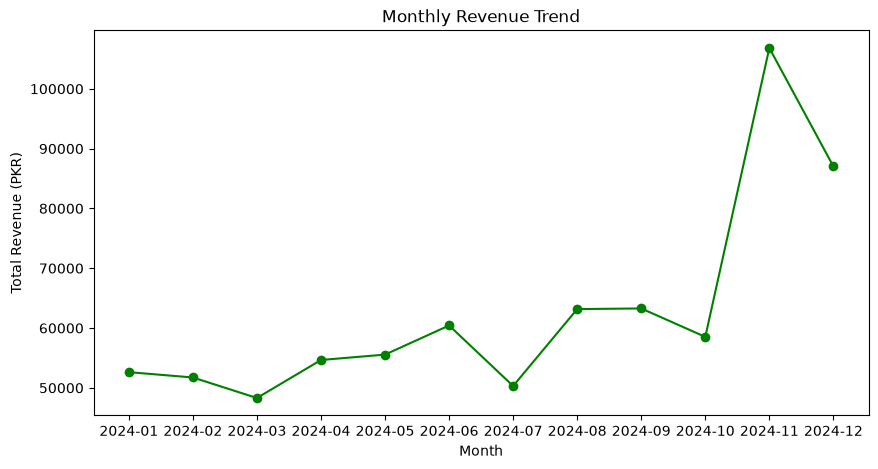

In [65]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.to_period("M")
monthly_revenue = df.groupby("month")["Final_amount"].sum()
plt.figure(figsize=(10, 5))

plt.plot(monthly_revenue.index.astype(str),
         monthly_revenue.values,
         marker="o",
         color="green")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (PKR)")
plt.show()

4. Horizontal Bar chart__Top 10 customers by total spending

<function matplotlib.pyplot.show(close=None, block=None)>

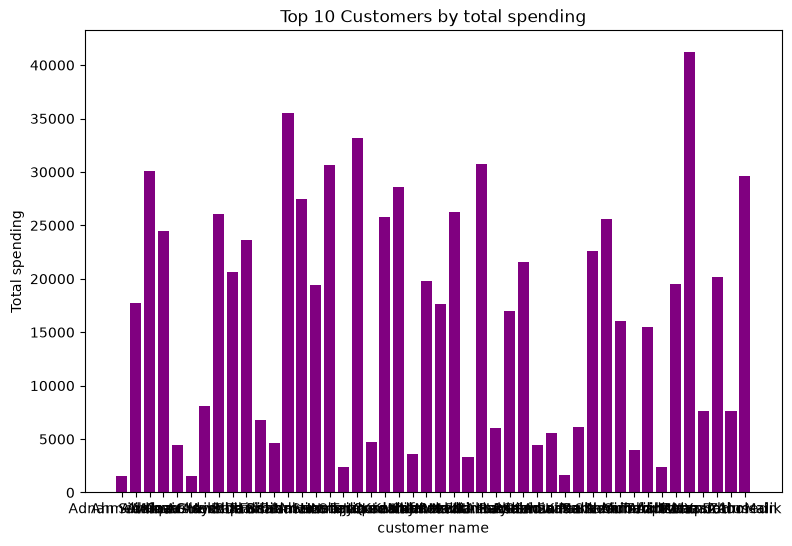

In [ ]:
top_customers=df.groupby("customer_name")["Final_amount"].sum()
plt.figure(figsize=(9,6))
plt.bar(top_customers.index,top_customers.values,color="purple")
plt.title("Top 10 Customers by total spending")
plt.xlabel("customer name")
plt.ylabel("Total spending")
plt.show

5.Grouped bar chart __revenue by category for male vs female customers

<function matplotlib.pyplot.show(close=None, block=None)>

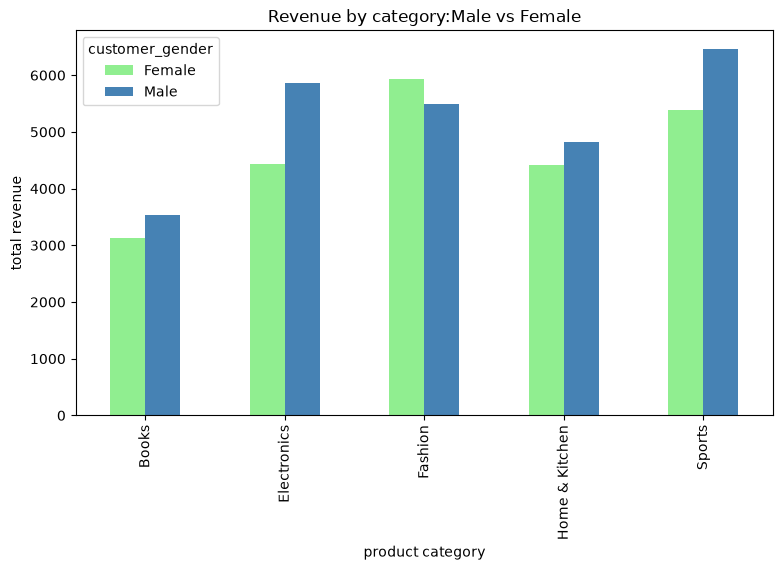

In [ ]:
gender_revenue=df.pivot_table(
    index="category",
    columns="customer_gender",
    values="Final_amount",
)
gender_revenue.plot(
    kind="bar",
    figsize=(9,5),
    color=["lightgreen","steelblue"]
)
plt.title("Revenue by category:Male vs Female")
plt.xlabel("product category")
plt.ylabel("total revenue")
plt.show

Task7: Matplotlib_pie charts,histograms & box plots

1. Pie chart__order status Distribution (Delivered/canceled/returned) with percentage labels

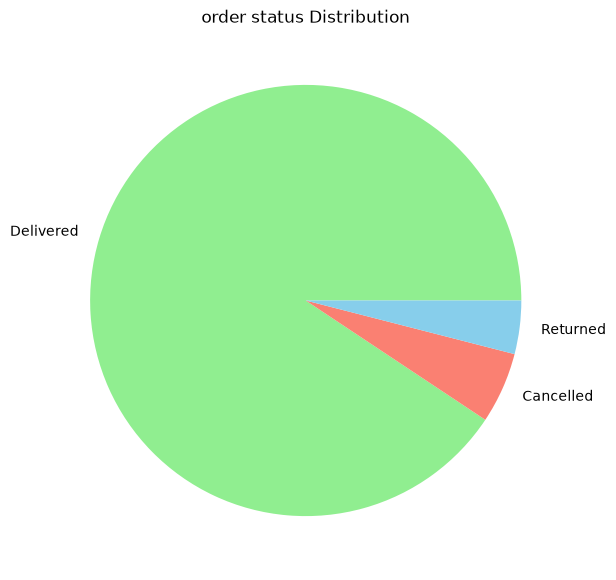

In [ ]:
status=df["order_status"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(status,labels=status.index,colors=["lightgreen","salmon","skyblue"])
plt.title("order status Distribution")
plt.show()

2. pie chart__Payment method distribution

<function matplotlib.pyplot.show(close=None, block=None)>

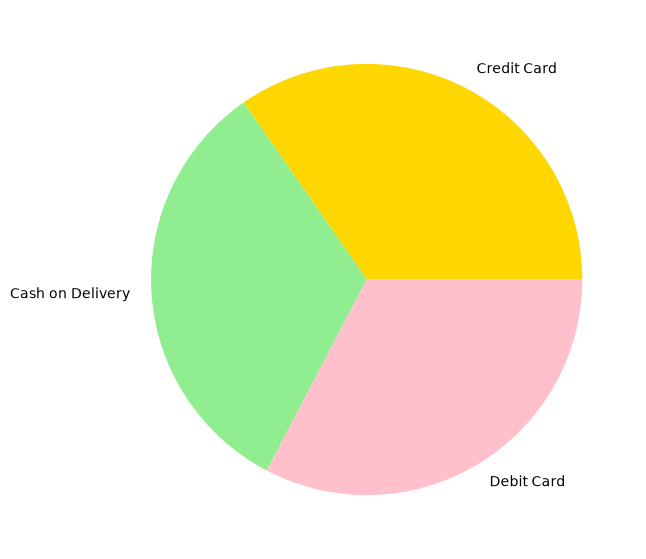

In [ ]:
payment=df["payment_method"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(payment,labels=payment.index,colors=["gold","lightgreen","pink"])
plt.show

3. Histogram __Distribution of customer Ages

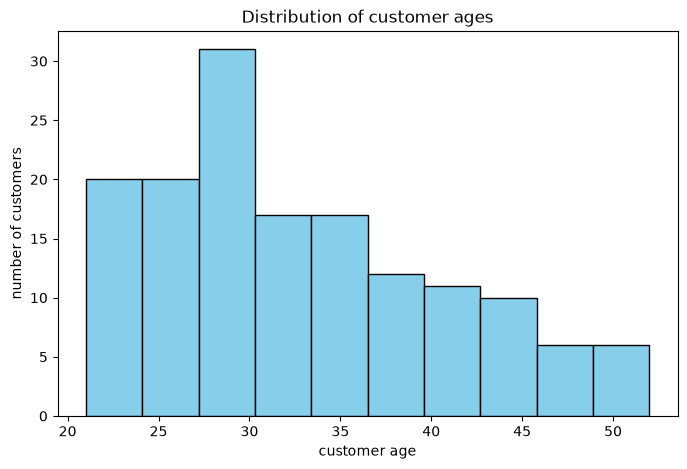

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["customer_age"],bins=10,color="skyblue",edgecolor="black")
plt.title("Distribution of customer ages")
plt.xlabel("customer age")
plt.ylabel("number of customers")
plt.show()

4.Histogram __Distribution of Final amount

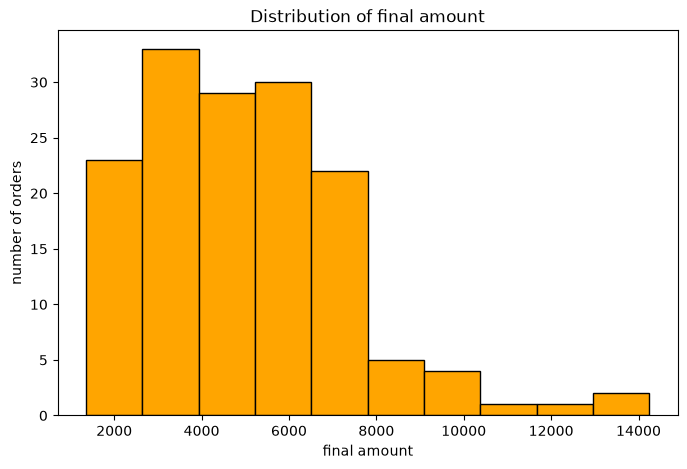

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["Final_amount"],bins=10,color="orange",edgecolor="black")
plt.title("Distribution of final amount")
plt.xlabel("final amount")
plt.ylabel("number of orders")
plt.show()

10. Box plot__final amount by product category

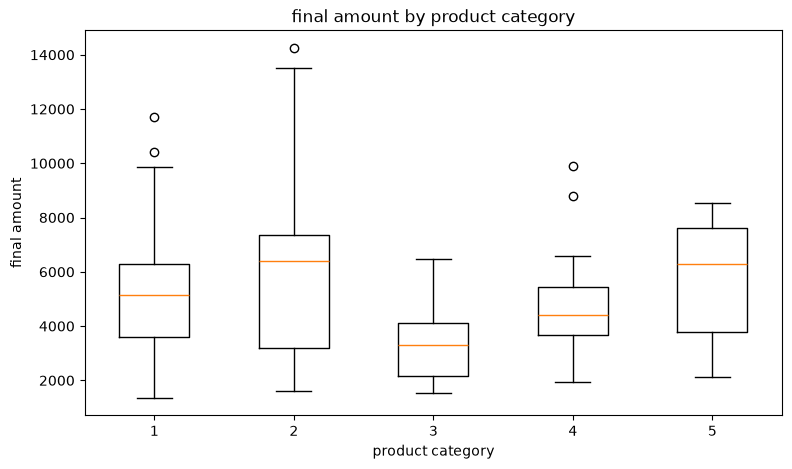

In [ ]:
categories=df["category"].unique()
data=[df[df["category"]==category]["Final_amount"].dropna()
      for category in categories]
plt.figure(figsize=(9,5))
plt.boxplot(data,label=categories)
plt.title("final amount by product category")
plt.xlabel("product category")
plt.ylabel("final amount")
plt.show()

Task8: Plotly_interactive visualizations

1. interactive bar chart __Revenue by city(use color parameter,add text labels on bars)

In [ ]:
fig = px.bar(
    city_revenue,
    x="customer_city",
    y="Final_amount",
    title="Revenue by City"
)

fig.update_traces(marker_color="darkgreen")

fig.show()

2. interactive scater plot __Customer age vs Final amount (color by categor,hover should show customer name,product and city)


In [ ]:
fig = px.scatter(
    df,
    x="customer_age",
    y="Final_amount",
    color="category",
    hover_data=["customer_name", "product_name", "customer_city"],
    title="Customer Age vs Final Amount"
)

fig.show()

3. interactive pie chart __orders by category (with hole for donut style)

In [ ]:
category_orders = df["category"].value_counts().reset_index()
category_orders.columns = ["category", "orders"]

fig = px.pie(
    category_orders,
    names="category",
    values="orders",
    hole=0.4,
    title="Orders by Category"
)

fig.show()

4. interactive line chart__Monyhly reveue trend with markers(add hover details)

In [ ]:
monthly_revenue = df.groupby("order_month_name")["Final_amount"].sum().reset_index()

fig = px.line(
    monthly_revenue,
    x="order_month_name",
    y="Final_amount",
    markers=True,
    hover_data=["Final_amount"],
    title="Monthly Revenue Trend"
)

fig.show()

<h1>Task 9: Business Questions</H1> —
  <h0>Q1: Which city is the most profitable for ShopSmart? Should the company invest more in marketing there? Justify with revenue numbers</H0>.

  ans1: Karachi generated the highest revenue of PKR 160,620, followed by Lahore with PKR 143,045 and Islamabad with PKR 121,140. Karachi therefore has the highest sales revenue, so ShopSmart could consider increasing marketing activities there while continuing to monitor the results.
  
  Q2: Which product category generates the highest revenue? Which category has the highest customer satisfaction (rating)? Are they the same?
   
 ans2: Electronics generated the highest revenue of PKR 211,850, followed by Sports with PKR 207,970. However, Books had the highest customer satisfaction with an average rating of 4.63. Therefore, the category with the highest revenue and the category with the highest rating are not the same.

  Q3: Are discounts helping increase sales or hurting revenue? Compare the average discount percentage with revenue across categories.

 ans3:Electronics generated PKR 211,850 with an average discount of 10.12%, while Sports generated PKR 207,970 with only a 4.57% average discount. Home & Kitchen had the highest average discount of 10.16% but generated PKR 142,737.50. This shows that higher discounts do not always result in higher revenue.
  
  
  Q4: What is the overall cancellation and return rate? Is it a cause for concern? Which city or product has the worst cancellation rate? 
   
  ans4:There were 8 cancelled orders (5.33%) and 6 returned orders (4%) out of 150 orders. Together, 9.33% of orders were either cancelled or returned, so these orders should be monitored. Lahore and Quetta had the highest number of cancellations, with 3 cancellations each.
   
   Q5:  Who are the top 5 most loyal (repeat) customers? What products do they usually buy? What is their average spending?
   
  ans5:The top five repeat customers were Ali Khan (7 orders), Sara Ahmed (6), Fatima Noor (6), Usman Ali (6), and Hina Tariq (6). They are the customers with the highest number of orders in the dataset. The current notebook does not calculate their individual products and average spending, so those figures should be calculated before completing this answer.



    Q6: Which payment method is most popular? Is there a relationship between payment method and order value? 

  ans6: Credit Card was the most frequently used payment method. The average order values were PKR 5,103.83 for Cash on Delivery, PKR 5,057.65 for Debit Card, and PKR 4,894.90 for Credit Card. Therefore, order values differ somewhat by payment method, with Cash on Delivery having the highest average order value.
    
    Q7: Which age group spends the most money? Which age group orders the most frequently? Should ShopSmart target a specific age group in their ads? 

  ans7:The Adult age group had the highest number of orders with 77 orders, followed by Middle Aged with 37, Young Adult with 24, and Senior with 12. The current notebook does not calculate total spending by age group, so the highest-spending age group cannot be stated accurately without that calculation.  
    
    Q8: Is there a seasonal trend in sales? Which quarter performed best and why do you think that is? 
    
  ans8: There is a clear increase in revenue toward the end of the year. Q4 performed best with PKR 252,375, compared with Q3 at PKR 176,757.50, Q2 at PKR 170,650, and Q1 at PKR 152,665. November was also the highest-revenue month with PKR 106,825, which may indicate stronger end-of-year demand.

    Q9: How does customer rating vary across categories? Which category needs improvement? 

  ans9:Books had the highest average rating of 4.63, followed by Electronics at 4.10, Sports at 4.14, and Fashion at 4.16. Home & Kitchen had the lowest rating at 3.77, so this category needs the most attention to improve customer satisfaction.

    Q10: Based on your entire analysis, write 5 strategic recommendations for ShopSmart's management team for the year 2025. 

  ans10:  
  1.Increase marketing efforts in Karachi, which generated the highest revenue of PKR 160,620.
  2.Focus on Electronics, which generated the highest category revenue of PKR 211,850.
  3.Review discount strategies because higher discounts did not always produce higher revenue.
  4.Investigate cancellations and returns, especially in Lahore and Quetta.
  5.Improve Home & Kitchen products and services because its average rating was only 3.77, the lowest among the categories.